# Laboratorium 1 – Zadanie 2
## Dobór zmiennych do modelu wieloczynnikowego – BodyFat

### Cel analizy

Celem zadania jest zbudowanie modelu regresji pozwalającego
przewidywać procent tkanki tłuszczowej (`Pct.BF`) na podstawie
zmiennych opisujących budowę ciała badanych osób.

Analiza obejmuje:
- eksplorację i przygotowanie danych,
- wybór procedury eliminacji zmiennych,
- budowę modelu regresji wielorakiej,
- ocenę jakości i diagnostykę modelu,
- budowę dodatkowych modeli dla innych zmiennych objaśnianych.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.api as sm
import statsmodels.formula.api as smf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

pd.set_option("display.max_columns", None)
pd.set_option("display.precision", 3)

sns.set_theme(style="whitegrid")

In [8]:
from pathlib import Path
import pandas as pd

DATA_PATH = Path("../data/raw/MED-lab-1-Zadanie-2-Dobor zmiennych-bodyfat-dane-i-opis.txt")
df = pd.read_csv(
    DATA_PATH,
    sep="\t",
    skiprows=10
)

display(df)

,Density,Pct.BF,Age,Weight,Height,Neck,Chest,Abdomen,Waist,Hip,Thigh,Knee,Ankle,Bicep,Forearm,Wrist
0,1.071,12.3,23,154.25,67.75,36.2,93.1,85.2,33.543,94.5,59.0,37.3,21.9,32.0,27.4,17.1
1,1.085,6.1,22,173.25,72.25,38.5,93.6,83.0,32.677,98.7,58.7,37.3,23.4,30.5,28.9,18.2
2,1.041,25.3,22,154.00,66.25,34.0,95.8,87.9,34.606,99.2,59.6,38.9,24.0,28.8,25.2,16.6
3,1.075,10.4,26,184.75,72.25,37.4,101.8,86.4,34.016,101.2,60.1,37.3,22.8,32.4,29.4,18.2
4,1.034,28.7,24,184.25,71.25,34.4,97.3,100.0,39.370,101.9,63.2,42.2,24.0,32.2,27.7,17.7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
245,1.074,11.0,70,134.25,67.00,34.9,89.2,83.6,32.913,88.8,49.6,34.8,21.5,25.6,25.7,18.5
246,1.024,33.6,72,201.00,69.75,40.9,108.5,105.0,41.339,104.5,59.6,40.8,23.2,35.2,28.6,20.1
247,1.033,29.3,72,186.75,66.00,38.9,111.1,111.5,43.898,101.7,60.3,37.3,21.5,31.3,27.2,18.0
248,1.040,26.0,72,190.75,70.50,38.9,108.3,101.3,39.882,97.8,56.0,41.6,22.7,30.5,29.4,19.8


In [15]:
print("Wymiary zbioru: ", df.shape)
print("Nazwy kolumn: ", df.columns)
print("Typy danych: ", df.dtypes)


print("Brakujące wartości:")
print(df.isna().sum())

print("\nLiczba duplikatów:", df.duplicated().sum())

Wymiary zbioru:  (250, 16)
Nazwy kolumn:  Index(['Density', 'Pct.BF', 'Age', 'Weight', 'Height', 'Neck', 'Chest',
       'Abdomen', 'Waist', 'Hip', 'Thigh', 'Knee', 'Ankle', 'Bicep', 'Forearm',
       'Wrist'],
      dtype='str')
Typy danych:  Density    float64
Pct.BF     float64
Age          int64
Weight     float64
Height     float64
Neck       float64
Chest      float64
Abdomen    float64
Waist      float64
Hip        float64
Thigh      float64
Knee       float64
Ankle      float64
Bicep      float64
Forearm    float64
Wrist      float64
dtype: object
Brakujące wartości:
Density    0
Pct.BF     0
Age        0
Weight     0
Height     0
Neck       0
Chest      0
Abdomen    0
Waist      0
Hip        0
Thigh      0
Knee       0
Ankle      0
Bicep      0
Forearm    0
Wrist      0
dtype: int64

Liczba duplikatów: 0


# Wnioski po wstępnym załadowaniu danych

1. Dane zostały poprawnie wczytane.
2. Zbiór zawiera 250 obserwacji i 16 zmiennych.
3. Wszystkie kolumny mają numeryczne typy danych.
4. Nie stwierdzono brakujących wartości.
5. Nie stwierdzono zduplikowanych obserwacji.

Na tym etapie nie ma potrzeby uzupełniania brakujących
wartości ani usuwania duplikatów.

Możemy poprowadzić dalszą analiza zmiennych pod kątem
ich przydatności do modelowania współliniowości.

# Eksploracyjna analiza danych

## Statystyki opisowe

W pierwszej kolejności analizujemy podstawowe statystyki
opisowe wszystkich zmiennych. Pozwolą one ocenić skalę
wartości, zróżnicowanie danych oraz potencjalne obserwacje
odstające.

In [18]:
stats = df.describe().T

stats["CV (%)"] = (
    stats["std"] / stats["mean"] * 100
)

display(stats.round(3))

,count,mean,std,min,25%,50%,75%,max,CV (%)
Density,250.0,1.056,0.019,0.995,1.042,1.055,1.070,1.109,1.788
Pct.BF,250.0,19.032,8.294,0.000,12.425,19.200,25.200,47.500,43.580
Age,250.0,44.884,12.652,22.000,35.250,43.000,54.000,81.000,28.189
Weight,250.0,178.083,27.035,118.500,158.500,176.125,196.750,262.750,15.181
Height,250.0,70.303,2.617,64.000,68.250,70.000,72.250,77.750,3.722
Neck,250.0,37.945,2.290,31.100,36.400,38.000,39.400,43.900,6.036
Chest,250.0,100.662,8.154,79.300,94.250,99.600,105.300,128.300,8.100
Abdomen,250.0,92.287,10.207,69.400,84.525,90.900,99.175,126.200,11.061
Waist,250.0,36.333,4.019,27.323,33.278,35.787,39.045,49.685,11.061
Hip,250.0,99.651,6.444,85.000,95.500,99.300,103.175,125.600,6.466


## Macierz korelacji

W celu zbadania zależności pomiędzy zmiennymi obliczono
macierz korelacji. 



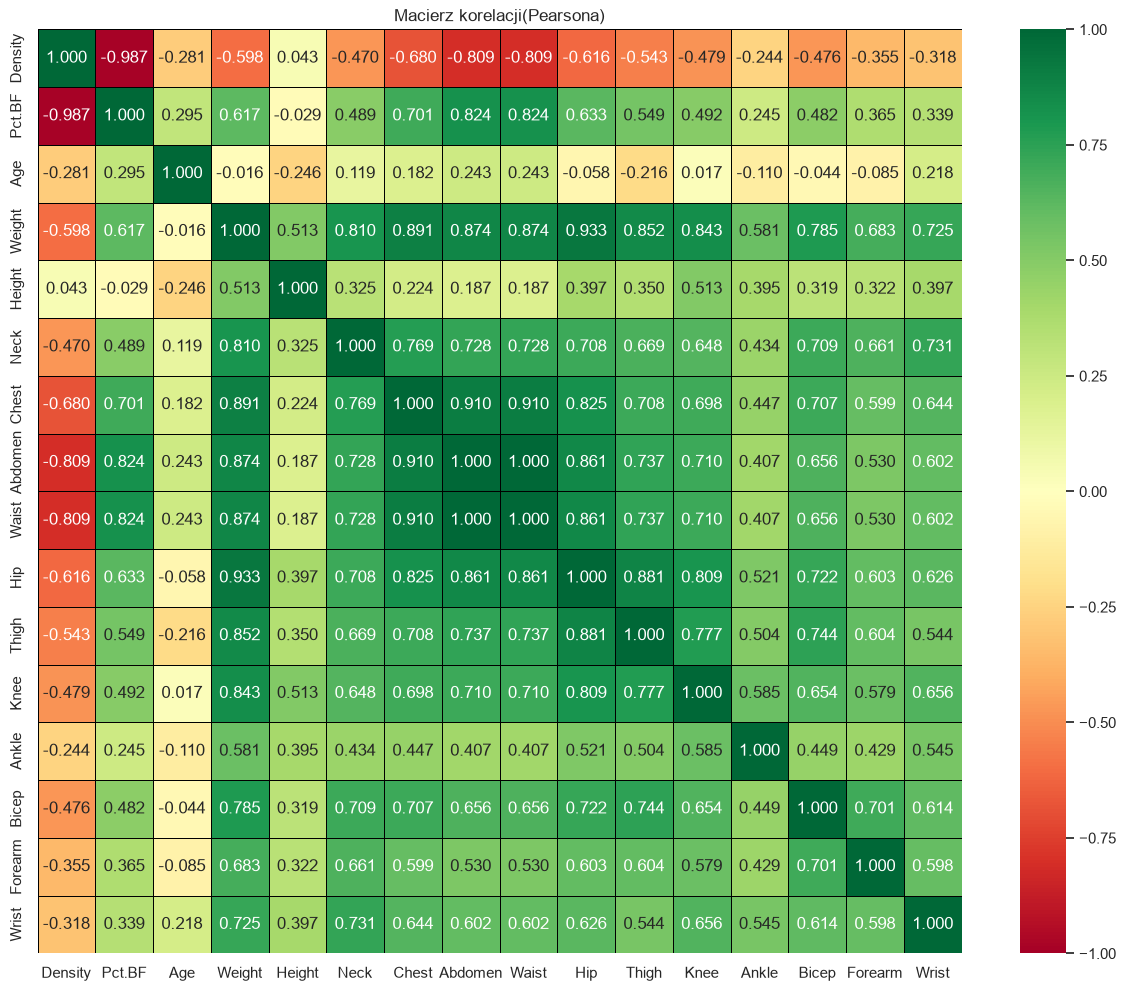

In [26]:
correlation_matrix = df.corr(numeric_only=True)

plt.figure(figsize=(15,12))

sns.heatmap(correlation_matrix,
            annot=True,
            cmap="RdYlGn",
            fmt=".3f",
            vmin=-1, vmax=1,
            linewidths=0.5,
            linecolor="black",
            square=True,
           )

plt.title("Macierz korelacji(Pearsona)")
plt.show()

## Przygotowanie danych do modelowania

Zmienną objaśnianą w głównym modelu jest `Pct.BF`.

Ze zbioru predyktorów wykluczono:
- `Waist` – zawiera te same informacje co `Abdomen`, ale wyrażone w innych jednostkach. Pozostawiono `Abdomen` w centymetrach.
- `Density` – zmienna ta jest silnie powiązana z procentem tkanki tłuszczowej i może być wykorzystana do jego wyznaczenia.
Pozostałe zmienne traktujemy jako kandydatów na predyktory.

In [29]:
target = "Pct.BF"

X = df.drop(columns = ["Pct.BF", "Density", "Waist"])
Y = df[target]

print("Lizba obserwacji", X.shape[0])
print("Liczba predykatów:", X.shape[1])

display(X)

Lizba obserwacji 250
Liczba predykatów: 13


,Age,Weight,Height,Neck,Chest,Abdomen,Hip,Thigh,Knee,Ankle,Bicep,Forearm,Wrist
0,23,154.25,67.75,36.2,93.1,85.2,94.5,59.0,37.3,21.9,32.0,27.4,17.1
1,22,173.25,72.25,38.5,93.6,83.0,98.7,58.7,37.3,23.4,30.5,28.9,18.2
2,22,154.00,66.25,34.0,95.8,87.9,99.2,59.6,38.9,24.0,28.8,25.2,16.6
3,26,184.75,72.25,37.4,101.8,86.4,101.2,60.1,37.3,22.8,32.4,29.4,18.2
4,24,184.25,71.25,34.4,97.3,100.0,101.9,63.2,42.2,24.0,32.2,27.7,17.7
...,...,...,...,...,...,...,...,...,...,...,...,...,...
245,70,134.25,67.00,34.9,89.2,83.6,88.8,49.6,34.8,21.5,25.6,25.7,18.5
246,72,201.00,69.75,40.9,108.5,105.0,104.5,59.6,40.8,23.2,35.2,28.6,20.1
247,72,186.75,66.00,38.9,111.1,111.5,101.7,60.3,37.3,21.5,31.3,27.2,18.0
248,72,190.75,70.50,38.9,108.3,101.3,97.8,56.0,41.6,22.7,30.5,29.4,19.8


## Podział danych na zbiór treningowy i testowy

Dane podzielono na dwa podzbiory:
- **Zbiór treningowy (80%)** – wykorzystywany do budowy i wyboru modeli.
- **Zbiór testowy (20%)** – wykorzystywany do końcowej oceny jakości predykcji na niewykorzystanych wcześniej obserwacjach.

Zastosowano stałe ziarno generatora liczb pseudolosowych (`random_state=4`), aby zapewnić powtarzalność wyników eksperymentu.

In [30]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X,
    Y,
    test_size=0.2,
    random_state=4 #if you know you know
)

print("Zbiór treningowy:", X_train.shape)
print("Zbiór testowy:", X_test.shape)

Zbiór treningowy: (200, 13)
Zbiór testowy: (50, 13)


## Porównanie modeli regresji o różnej liczbie predyktorów

W celu zbadania wpływu liczby i rodzaju zmiennych objaśniających
na jakość modelu zaproponowano zestaw modeli regresji liniowej.

Analizę rozpoczęto od modeli jednoczynnikowych, wykorzystujących
pojedyncze predyktory. Następnie zaproponowano modele
wieloczynnikowe, łączące dwie i trzy zmienne.

Na końcu wyniki zostaną porównane z modelem pełnym,
wykorzystującym wszystkie dostępne predyktory.

Porównanie pozwoli ocenić, czy zwiększenie liczby zmiennych
objaśniających rzeczywiście poprawia jakość predykcji.

## Proponowane modele regresji

W celu zbadania wpływu poszczególnych zmiennych objaśniających na `Pct.BF` zaproponowano zestaw modeli regresji liniowej o różnej liczbie predyktorów.

### Modele jednoczynnikowe

- **M1:** `Pct.BF ~ Height`
- **M2:** `Pct.BF ~ Weight`
- **M3:** `Pct.BF ~ Abdomen`

### Modele dwuczynnikowe

- **M4:** `Pct.BF ~ Weight + Height`
- **M5:** `Pct.BF ~ Weight + Abdomen`
- **M6:** `Pct.BF ~ Height + Abdomen`

### Model trójczynnikowy

- **M7:** `Pct.BF ~ Weight + Height + Abdomen`

### Model pełny

- **M8:** `Pct.BF ~ Age + Weight + Height + Neck + Chest + Abdomen + Hip + Thigh + Knee + Ankle + Bicep + Forearm + Wrist`

### Cel porównania

Celem analizy jest sprawdzenie, jak zwiększanie liczby predyktorów wpływa na dopasowanie modelu i jakość predykcji. Wyniki poszczególnych modeli zostaną porównane z wykorzystaniem współczynnika determinacji $R^2$, skorygowanego współczynnika determinacji $R^2_{adj}$, kryterium AIC oraz błędów predykcji MAE i RMSE.

Na podstawie uzyskanych wyników zostanie ocenione, czy bardziej rozbudowane modele zapewniają istotną poprawę jakości predykcji.

### Modele jednoczynnikowe

W pierwszym etapie dopasowano trzy modele regresji liniowej,
z których każdy wykorzystuje tylko jedną zmienną objaśniającą:
`Height`, `Weight` lub `Abdomen`.

Pozwoli to ocenić indywidualną przydatność poszczególnych
predyktorów w przewidywaniu procentu tkanki tłuszczowej.

In [41]:
# M1: Pct.Bf ~ Height 
model_m1 = sm.OLS(
    Y_train,
    sm.add_constant(X_train[["Height"]])
).fit()

# M2: Pct.Bf ~ Weight 
model_m2 = sm.OLS(
    Y_train,
    sm.add_constant(X_train[["Weight"]])
).fit()

# M3: Pct.Bf ~ Abdomen
model_m3 = sm.OLS(
    Y_train,
    sm.add_constant(X_train[["Abdomen"]])
).fit()

'''
print("MODEL M1: Height")
print(model_m1.summary())

print("\nMODEL M2: Weight")
print(model_m2.summary())

print("\nMODEL M3: Abdomen")
print(model_m3.summary())
'''

'\nprint("MODEL M1: Height")\nprint(model_m1.summary())\n\nprint("\nMODEL M2: Weight")\nprint(model_m2.summary())\n\nprint("\nMODEL M3: Abdomen")\nprint(model_m3.summary())\n'

In [38]:
models = {
    "M1 - Height": model_m1,
    "M2 - Weight": model_m2,
    "M3 - Abdomen": model_m3
}

results = []

for name, model in models.items():
    results.append({
        "Model": name,
        "R²": model.rsquared,
        "R² adjusted": model.rsquared_adj,
        "F-statistic": model.fvalue,
        "Model p-value": model.f_pvalue,
        "AIC": model.aic
    })

comparison = pd.DataFrame(results)

display(comparison.round(4))

,Model,R²,R² adjusted,F-statistic,Model p-value,AIC
0,M1 - Height,3.000e-04,-0.005,0.064,0.8,1397.509
1,M2 - Weight,3.571e-01,0.354,109.987,0.0,1309.216
2,M3 - Abdomen,6.487e-01,0.647,365.603,0.0,1188.358


### Porównanie modeli jednoczynnikowych

W pierwszym etapie analizy zbudowano trzy modele regresji liniowej, wykorzystujące pojedynczo zmienne `Height`, `Weight` oraz `Abdomen`.

Najniższą jakość dopasowania uzyskano dla modelu wykorzystującego zmienną `Height` (\(R^2 = 0{,}0003\)). Oznacza to, że wzrost praktycznie nie wyjaśnia zmienności procentu tkanki tłuszczowej w rozpatrywanym modelu liniowym.

Model wykorzystujący zmienną `Weight` osiągnął \(R^2 = 0{,}3571\), natomiast najlepsze dopasowanie uzyskano dla zmiennej `Abdomen` (\(R^2 = 0{,}6487\)).

Na podstawie współczynnika determinacji oraz kryterium AIC stwierdzono, że spośród analizowanych pojedynczych predyktorów największą wartość objaśniającą ma obwód brzucha (`Abdomen`). Zmienna ta zostanie uwzględniona w kolejnych modelach wieloczynnikowych.

### Modele dwuczynnikowe

W kolejnym etapie zbudowano modele regresji dwuargumentowej,
wykorzystujące po dwie zmienne objaśniające.

Sprawdzimy, czy połączenie informacji
pochodzących z dwóch predyktorów poprawia jakość modelu
w porównaniu z modelami jednoczynnikowymi.

In [43]:
# M4: Pct.BF ~ Weight + Height
model_m4 = sm.OLS(
    Y_train,
    sm.add_constant(X_train[["Weight", "Height"]])
).fit()

# M5: Pct.BF ~ Weight + Abdomen
model_m5 = sm.OLS(
    Y_train,
    sm.add_constant(X_train[["Weight", "Abdomen"]])
).fit()

# M6: Pct.BF ~ Height + Abdomen
model_m6 = sm.OLS(
    Y_train,
    sm.add_constant(X_train[["Height", "Abdomen"]])
).fit()

In [44]:
models.update({
    "M4 - Weight + Height": model_m4,
    "M5 - Weight + Abdomen": model_m5,
    "M6 - Height + Abdomen": model_m6
})

In [45]:
results = []

for name, model in models.items():
    results.append({
        "Model": name,
        "R2": model.rsquared,
        "Adjusted R2": model.rsquared_adj,
        "F-statistic": model.fvalue,
        "Model p-value": model.f_pvalue,
        "AIC": model.aic
    })

comparison = pd.DataFrame(results)

display(comparison.round(4))

,Model,R2,Adjusted R2,F-statistic,Model p-value,AIC
0,M1 - Height,3.000e-04,-0.005,0.064,0.8,1397.509
1,M2 - Weight,3.571e-01,0.354,109.987,0.0,1309.216
2,M3 - Abdomen,6.487e-01,0.647,365.603,0.0,1188.358
3,M4 - Weight + Height,4.998e-01,0.495,98.424,0.0,1261.021
4,M5 - Weight + Abdomen,6.880e-01,0.685,217.158,0.0,1166.654
5,M6 - Height + Abdomen,6.816e-01,0.678,210.860,0.0,1170.685


In [46]:
display(model_m5.summary())

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 Pct.BF   R-squared:                       0.688
Model:                            OLS   Adj. R-squared:                  0.685
Method:                 Least Squares   F-statistic:                     217.2
Date:                Sun, 08 Nov 2026   Prob (F-statistic):           1.52e-50
Time:                        20:31:56   Log-Likelihood:                -580.33
No. Observations:                 200   AIC:                             1167.
Df Residuals:                     197   BIC:                             1177.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        -46.4716      3.150    -14.751      0.000     -52.684     -40.259
Weight        -0.1212      0.024     -4.979      0.000      -0.169      -0.073
Abdomen        0.9438      0.065     14.452      0.000       0.815       1.073
==============================================================================
Omnibus:                        4.800   Durbin-Watson:                   1.962
Prob(Omnibus):                  0.091   Jarque-Bera (JB):                2.836
Skew:                          -0.002   Prob(JB):                        0.242
Kurtosis:                       2.417   Cond. No.                     2.01e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 2.01e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [47]:
from statsmodels.stats.anova import anova_lm

anova_lm(model_m3, model_m5)


,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,198.0,4368.733,0.0,NaN,NaN,NaN
1,197.0,3880.457,1.0,488.276,24.788,1.393e-06


### Analiza modelu M5 – Weight i Abdomen

Model M5 wykorzystujący zmienne `Weight` oraz `Abdomen` osiągnął współczynnik determinacji $R^2 = 0{,}6880$ oraz skorygowany współczynnik determinacji $R^2_{adj} = 0{,}685$.

Oba predyktory okazały się istotne statystycznie przy poziomie istotności $\alpha = 0{,}05$.

Współczynnik przy zmiennej `Weight` wyniósł -0,1212, natomiast przy zmiennej `Abdomen` wyniósł 0,9438.

Dodatkowo przeprowadzono test porównujący modele M3 i M5. Uzyskana wartość statystyki F wyniosła 24,788, a wartość p-value wyniosła $1{,}393 \cdot 10^{-6}$. Oznacza to, że dodanie zmiennej `Weight` do modelu zawierającego `Abdomen` istotnie poprawia jego dopasowanie.

W związku z tym model M5 uznano za lepszy od modelu M3 na podstawie analizy danych treningowych.

Co ciekawe nie wykazano Zależności między procentem tkanki tłuszcowej a wysokością i wagą

### Model trójczynnikowy

W kolejnym etapie zbudowano model regresji wielorakiej
wykorzystujący trzy zmienne objaśniające: `Weight`,
`Height` oraz `Abdomen`.

Celem jest sprawdzenie, czy uwzględnienie wzrostu
dostarcza dodatkowych informacji o procentowej zawartości
tkanki tłuszczowej po uwzględnieniu masy ciała
i obwodu brzucha.

In [53]:
# M7: Pct.BF ~ Weight + Height + Abdomen
model_m7 = sm.OLS(
    Y_train,
    sm.add_constant(X_train[["Weight", "Height", "Abdomen"]])
).fit()

models.update({
    "M7 - Weight + Height + Abdomen": model_m7
})

results = []

for name, model in models.items():
    results.append({
        "Model": name,
        "R2": model.rsquared,
        "Adjusted R2": model.rsquared_adj,
        "F-statistic": model.fvalue,
        "Model p-value": model.f_pvalue,
        "AIC": model.aic
    })

comparison = pd.DataFrame(results)

display(comparison.round(4))

display(model_m7.summary())

,Model,R2,Adjusted R2,F-statistic,Model p-value,AIC
0,M1 - Height,3.000e-04,-0.005,0.064,0.8,1397.509
1,M2 - Weight,3.571e-01,0.354,109.987,0.0,1309.216
2,M3 - Abdomen,6.487e-01,0.647,365.603,0.0,1188.358
3,M4 - Weight + Height,4.998e-01,0.495,98.424,0.0,1261.021
4,M5 - Weight + Abdomen,6.880e-01,0.685,217.158,0.0,1166.654
5,M6 - Height + Abdomen,6.816e-01,0.678,210.860,0.0,1170.685
6,M7 - Weight + Height + Abdomen,6.912e-01,0.686,146.249,0.0,1166.552


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 Pct.BF   R-squared:                       0.691
Model:                            OLS   Adj. R-squared:                  0.686
Method:                 Least Squares   F-statistic:                     146.2
Date:                Sun, 08 Nov 2026   Prob (F-statistic):           9.05e-50
Time:                        20:39:35   Log-Likelihood:                -579.28
No. Observations:                 200   AIC:                             1167.
Df Residuals:                     196   BIC:                             1180.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        -28.0556     13.179     -2.129      0.035     -54.046      -2.066
Weight        -0.0856      0.035     -2.470      0.014      -0.154      -0.017
Height        -0.2654      0.184     -1.439      0.152      -0.629       0.098
Abdomen        0.8778      0.080     11.022      0.000       0.721       1.035
==============================================================================
Omnibus:                        4.470   Durbin-Watson:                   1.981
Prob(Omnibus):                  0.107   Jarque-Bera (JB):                2.709
Skew:                          -0.002   Prob(JB):                        0.258
Kurtosis:                       2.430   Cond. No.                     8.95e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 8.95e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [50]:
anova_lm(model_m5, model_m7)

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,197.0,3880.457,0.0,NaN,NaN,NaN
1,196.0,3839.894,1.0,40.563,2.07,0.152


### Analiza modelu trójczynnikowego

W kolejnym etapie zbudowano model M7, wykorzystujący zmienne `Weight`, `Height` oraz `Abdomen`.

Model osiągnął współczynnik determinacji $R^2 = 0{,}69142$ oraz skorygowany współczynnik determinacji $R^2_{adj} = 0{,}686$. W porównaniu z modelem M5 uzyskano niewielką poprawę dopasowania.

Przeprowadzono test ANOVA w celu sprawdzenia, czy dodanie zmiennej `Height` do modelu M5 istotnie poprawia jego dopasowanie. Otrzymana wartość statystyki F wyniosła 2,07, a p-value wyniosło 0,152. Ponieważ wartość ta przekracza przyjęty poziom istotności $\alpha = 0{,}05$, nie stwierdzono statystycznie istotnej poprawy po dodaniu zmiennej `Height`.

W modelu M7 zmienna `Height` również nie okazała się istotna statystycznie (p-value = 0,152), podczas gdy `Weight` (p-value = 0,014) oraz `Abdomen` (p-value < 0,001) pozostały istotnymi predyktorami.

Wyniki sugerują, że uwzględnienie wzrostu nie wnosi wystarczającej dodatkowej informacji do modelu wykorzystującego masę ciała i obwód brzucha. Z tego względu prostszy model M5 pozostaje preferowanym rozwiązaniem spośród dotychczas analizowanych modeli.

### Model pełny – wykorzystanie wszystkich dostępnych predyktorów

W ostatnim etapie porównania modeli o różnej liczbie predyktorów zaproponowano model pełny, wykorzystujący wszystkie 13 dostępnych zmiennych objaśniających.

Model obejmuje następujące predyktory:

- `Age` – wiek,
- `Weight` – masa ciała,
- `Height` – wzrost,
- `Neck` – obwód szyi,
- `Chest` – obwód klatki piersiowej,
- `Abdomen` – obwód brzucha,
- `Hip` – obwód bioder,
- `Thigh` – obwód uda,
- `Knee` – obwód kolana,
- `Ankle` – obwód kostki,
- `Bicep` – obwód bicepsa,
- `Forearm` – obwód przedramienia,
- `Wrist` – obwód nadgarstka.

Ze zbioru predyktorów wykluczono wcześniej `Density` oraz `Waist`, ze względu na ryzyko wycieku informacji o zmiennej objaśnianej oraz powielanie informacji zawartej w zmiennej `Abdomen`.

Celem budowy modelu pełnego jest sprawdzenie, czy wykorzystanie wszystkich dostępnych pomiarów antropometrycznych i informacji o badanych osobach pozwala uzyskać lepsze dopasowanie niż w przypadku wcześniej analizowanych modeli o mniejszej liczbie predyktorów.

Wyniki modelu pełnego posłużą również jako punkt wyjścia do przeprowadzenia procedury eliminacji wstecznej, której celem będzie wyłonienie mniejszego zestawu zmiennych objaśniających.

In [55]:
# M8: model pełny – wszystkie 13 predyktorów
X_train_full = sm.add_constant(X_train)

model_m8 = sm.OLS(
    Y_train,
    X_train_full
).fit()

display(model_m8.summary())

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 Pct.BF   R-squared:                       0.728
Model:                            OLS   Adj. R-squared:                  0.709
Method:                 Least Squares   F-statistic:                     38.35
Date:                Sun, 08 Nov 2026   Prob (F-statistic):           1.19e-45
Time:                        20:42:34   Log-Likelihood:                -566.49
No. Observations:                 200   AIC:                             1161.
Df Residuals:                     186   BIC:                             1207.
Df Model:                          13                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         18.4377     26.805      0.688      0.492     -34.444      71.319
Age            0.0814      0.036      2.280      0.024       0.011       0.152
Weight         0.0313      0.075      0.418      0.676      -0.116       0.179
Height        -0.3784      0.223     -1.698      0.091      -0.818       0.061
Neck          -0.5702      0.257     -2.217      0.028      -1.078      -0.063
Chest         -0.1312      0.125     -1.052      0.294      -0.377       0.115
Abdomen        0.8210      0.104      7.872      0.000       0.615       1.027
Hip           -0.0963      0.173     -0.555      0.579      -0.439       0.246
Thigh          0.1310      0.177      0.742      0.459      -0.217       0.479
Knee          -0.0126      0.295     -0.043      0.966      -0.594       0.569
Ankle          0.1487      0.230      0.647      0.519      -0.305       0.603
Bicep          0.1247      0.187      0.666      0.506      -0.245       0.494
Forearm        0.2248      0.216      1.043      0.298      -0.200       0.650
Wrist         -1.8940      0.582     -3.252      0.001      -3.043      -0.745
==============================================================================
Omnibus:                        3.114   Durbin-Watson:                   1.987
Prob(Omnibus):                  0.211   Jarque-Bera (JB):                2.196
Skew:                          -0.058   Prob(JB):                        0.334
Kurtosis:                       2.500   Cond. No.                     2.45e+04
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 2.45e+04. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [57]:
anova_lm(model_m7, model_m8)

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,196.0,3839.894,0.0,NaN,NaN,NaN
1,186.0,3379.154,10.0,460.74,2.536,0.007


In [56]:
models.update({
    "M8 - Full model": model_m8
})

results = []

for name, model in models.items():
    results.append({
        "Model": name,
        "R2": model.rsquared,
        "Adjusted R2": model.rsquared_adj,
        "F-statistic": model.fvalue,
        "Model p-value": model.f_pvalue,
        "AIC": model.aic
    })

comparison = pd.DataFrame(results)

display(comparison.round(4))

#display(model_m7.summary())

,Model,R2,Adjusted R2,F-statistic,Model p-value,AIC
0,M1 - Height,3.000e-04,-0.005,0.064,0.8,1397.509
1,M2 - Weight,3.571e-01,0.354,109.987,0.0,1309.216
2,M3 - Abdomen,6.487e-01,0.647,365.603,0.0,1188.358
3,M4 - Weight + Height,4.998e-01,0.495,98.424,0.0,1261.021
4,M5 - Weight + Abdomen,6.880e-01,0.685,217.158,0.0,1166.654
5,M6 - Height + Abdomen,6.816e-01,0.678,210.860,0.0,1170.685
6,M7 - Weight + Height + Abdomen,6.912e-01,0.686,146.249,0.0,1166.552
7,M8 - Full model,7.283e-01,0.709,38.346,0.0,1160.988


### Analiza modelu pełnego M8

Model M8 wykorzystujący wszystkie 13 dostępnych predyktorów osiągnął współczynnik determinacji $R^2 = 0{,}7283$ oraz skorygowany współczynnik determinacji $R^2_{adj} = 0{,}709$. Model jako całość okazał się istotny statystycznie (p-value = $1{,}19 \cdot 10^{-45}$).

Analiza istotności poszczególnych współczynników wykazała, że przy poziomie istotności $\alpha = 0{,}05$ istotne statystycznie są zmienne `Age`, `Neck`, `Abdomen` oraz `Wrist`. Pozostałe predyktory nie osiągnęły przyjętego poziomu istotności.

Następnie przeprowadzono test ANOVA porównujący model M7, wykorzystujący trzy predyktory (`Weight`, `Height`, `Abdomen`), z modelem pełnym M8. Uzyskano wartość statystyki F = 2,536 oraz p-value = 0,007. Ponieważ p-value jest mniejsze od przyjętego poziomu istotności 0,05, stwierdzono, że dodanie pozostałych predyktorów łącznie powoduje statystycznie istotną poprawę dopasowania modelu.

Wynik ten wskazuje, że dodatkowe zmienne mogą wnosić informacje przydatne w wyjaśnianiu zmienności procentu tkanki tłuszczowej, nawet jeśli nie wszystkie z nich wykazują indywidualną istotność statystyczną.

Model pełny uzyskał lepsze dopasowanie niż wcześniej analizowane modele, jednak jego większa złożoność uzasadnia przeprowadzenie dalszej selekcji zmiennych w celu znalezienia bardziej oszczędnego rozwiązania.

### Ogólne podsumowanie porównania modeli

W ramach analizy zbudowano osiem modeli regresji liniowej, różniących się liczbą i rodzajem wykorzystanych predyktorów.

W modelach jednoczynnikowych najlepsze dopasowanie uzyskano dla zmiennej `Abdomen` $(R^2 = 0{,}6487$). Zmienna `Weight` również wykazała istotną zależność z procentem tkanki tłuszczowej, natomiast dla `Height` nie stwierdzono istotnej zależności liniowej.

W modelach dwuczynnikowych najlepszy wynik uzyskano dla kombinacji `Weight` i `Abdomen` (M5). Model osiągnął $R^2 = 0{,}6880$ oraz skorygowane $R^2 = 0{,}685$. Test ANOVA potwierdził, że dodanie zmiennej `Weight` do modelu zawierającego wyłącznie `Abdomen` istotnie poprawia jego dopasowanie.

Dodanie zmiennej `Height` do modelu M5 nie przyniosło statystycznie istotnej poprawy, co potwierdziło porównanie M5 i M7 (p-value = 0,152).

Najwyższe dopasowanie uzyskano dla modelu pełnego M8, wykorzystującego wszystkie 13 predyktorów. Osiągnął on $R^2 = 0{,}7283$ oraz skorygowane $R^2 = 0{,}709$. Test ANOVA wykazał również, że rozszerzenie modelu M7 do M8 istotnie poprawia jego dopasowanie (p-value = 0,007).

Dotychczasowe wyniki wskazują, że zwiększanie liczby predyktorów może poprawiać jakość dopasowania modelu, jednak nie wszystkie zmienne muszą wnosić istotną informację. Z tego względu kolejnym etapem analizy będzie przeprowadzenie eliminacji wstecznej, której celem jest wyznaczenie mniejszego zestawu predyktorów przy zachowaniu możliwie dobrej jakości modelu.

## Ocena jakości modeli na zbiorze testowym

Po dopasowaniu modeli na zbiorze treningowym przeprowadzono
ocenę ich zdolności predykcyjnych na niezależnym zbiorze testowym.

Do oceny wykorzystano:
- współczynnik determinacji R²,
- średni błąd bezwzględny MAE,
- pierwiastek średniego błędu kwadratowego RMSE.

Pozwoli to ocenić, czy modele zachowują dobrą jakość
predykcji dla obserwacji niewykorzystanych podczas uczenia.

In [60]:
# Określamy predyktory wykorzystywane przez poszczególne modele
model_features = {
    "M1 - Height": ["Height"],
    "M2 - Weight": ["Weight"],
    "M3 - Abdomen": ["Abdomen"],
    "M4 - Weight + Height": ["Weight", "Height"],
    "M5 - Weight + Abdomen": ["Weight", "Abdomen"],
    "M6 - Height + Abdomen": ["Height", "Abdomen"],
    "M7 - Weight + Height + Abdomen": ["Weight", "Height", "Abdomen"],
    "M8 - Full model": X_train.columns.tolist()
}

test_results = []

for name, model in models.items():

    features = model_features[name]

    X_test_model = sm.add_constant(
        X_test[features],
        has_constant="add"
    )

    Y_pred = model.predict(X_test_model)

    test_results.append({
        "Model": name,
        "R2 test": r2_score(Y_test, Y_pred),
        "MAE": mean_absolute_error(Y_test, Y_pred),
        "RMSE": np.sqrt(mean_squared_error(Y_test, Y_pred))
    })

test_comparison = pd.DataFrame(test_results)

display(test_comparison.round(4))

,Model,R2 test,MAE,RMSE
0,M1 - Height,-0.023,7.924,9.733
1,M2 - Weight,0.435,5.462,7.232
2,M3 - Abdomen,0.753,3.856,4.778
3,M4 - Weight + Height,0.654,4.691,5.664
4,M5 - Weight + Abdomen,0.811,3.534,4.183
5,M6 - Height + Abdomen,0.794,3.755,4.368
6,M7 - Weight + Height + Abdomen,0.811,3.572,4.184
7,M8 - Full model,0.797,3.724,4.333


## Porównanie jakości predykcyjnej modeli

Poniżej przedstawiono porównanie współczynnika determinacji
oraz błędów predykcji poszczególnych modeli na zbiorze testowym.
Pozwala to ocenić, jak liczba i rodzaj predyktorów wpływają
na zdolność modeli do przewidywania nowych obserwacji.

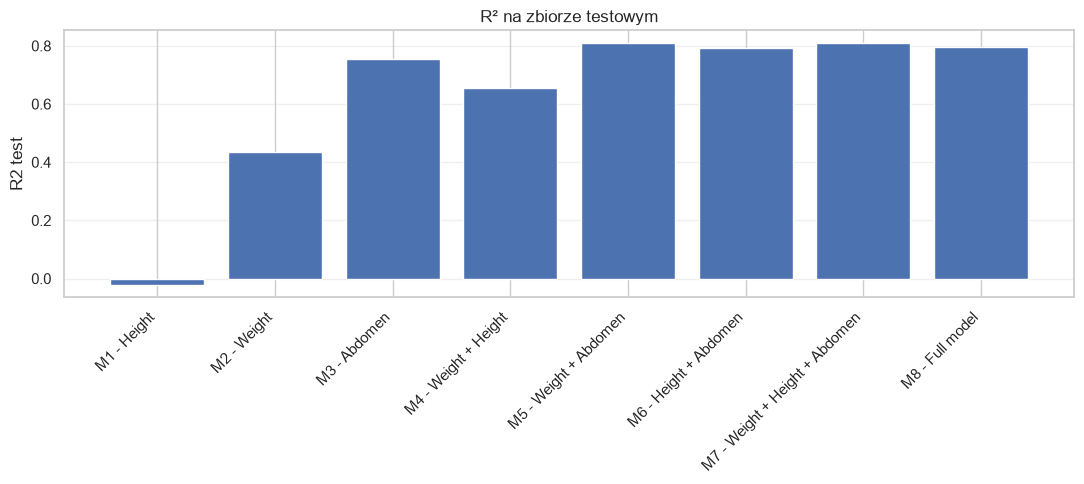

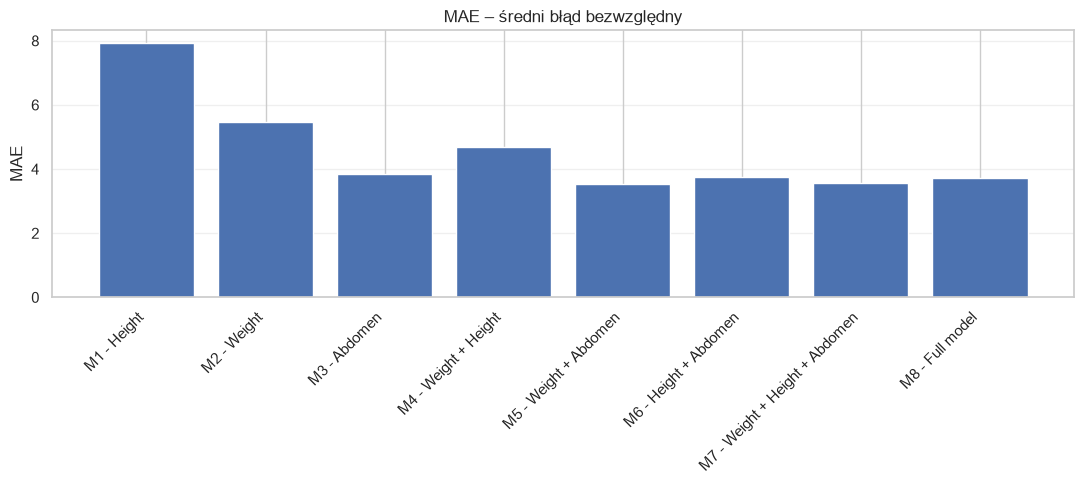

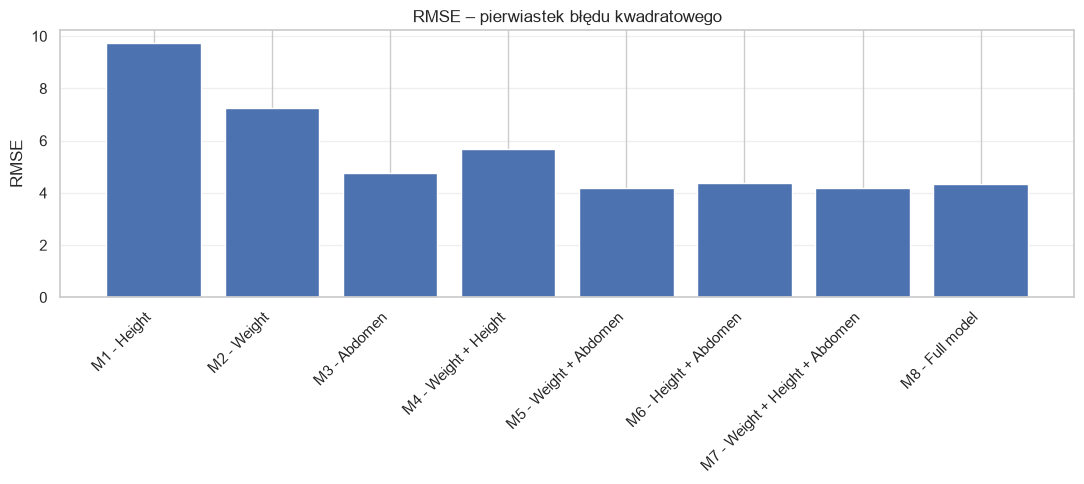

In [63]:
metrics = [
    ("R2 test", "R² na zbiorze testowym"),
    ("MAE", "MAE – średni błąd bezwzględny"),
    ("RMSE", "RMSE – pierwiastek błędu kwadratowego")
]

for metric, title in metrics:
    plt.figure(figsize=(11, 5))

    plt.bar(
        test_comparison["Model"],
        test_comparison[metric]
    )

    plt.title(title)
    plt.xticks(rotation=45, ha="right")
    plt.ylabel(metric)
    plt.grid(axis="y", alpha=0.3)

    plt.tight_layout()
    plt.show()

## Wizualizacja zależności między predyktorami a Pct.BF

W celu wizualnej oceny zależności pomiędzy wybranymi
zmiennymi objaśniającymi a procentem tkanki tłuszczowej
przygotowano wykresy rozrzutu wraz z dopasowanymi
liniami regresji.

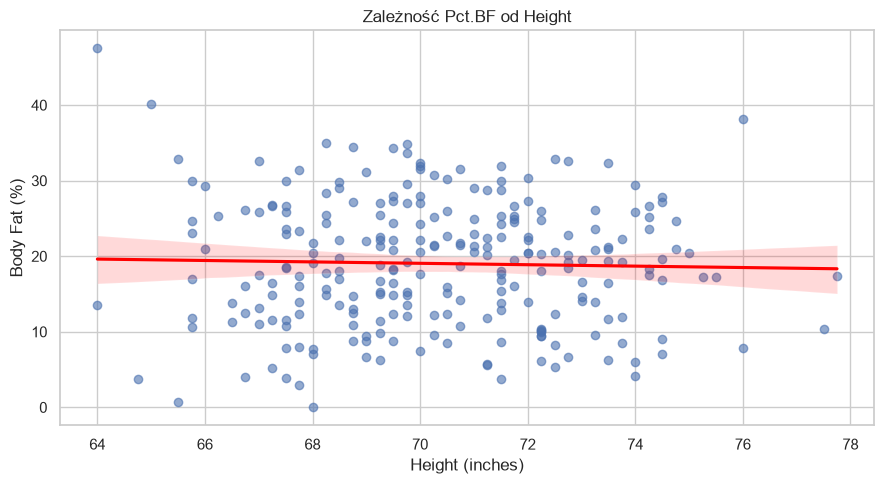

In [65]:
plt.figure(figsize=(9, 5))

sns.regplot(
    data=df,
    x="Height",
    y="Pct.BF",
    scatter_kws={"alpha": 0.6},
    line_kws={"color": "red"}
)

plt.title("Zależność Pct.BF od Height")
plt.xlabel("Height (inches)")
plt.ylabel("Body Fat (%)")
plt.tight_layout()
plt.show()

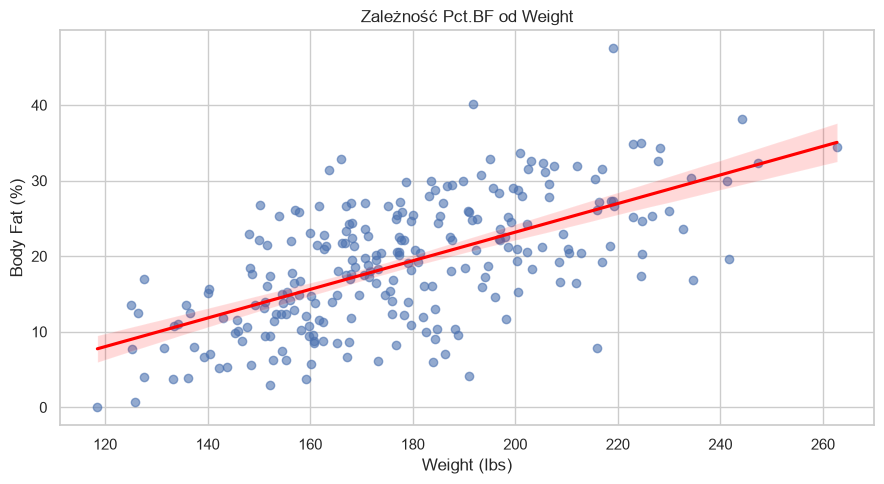

In [66]:
plt.figure(figsize=(9, 5))

sns.regplot(
    data=df,
    x="Weight",
    y="Pct.BF",
    scatter_kws={"alpha": 0.6},
    line_kws={"color": "red"}
)

plt.title("Zależność Pct.BF od Weight")
plt.xlabel("Weight (lbs)")
plt.ylabel("Body Fat (%)")
plt.tight_layout()
plt.show()

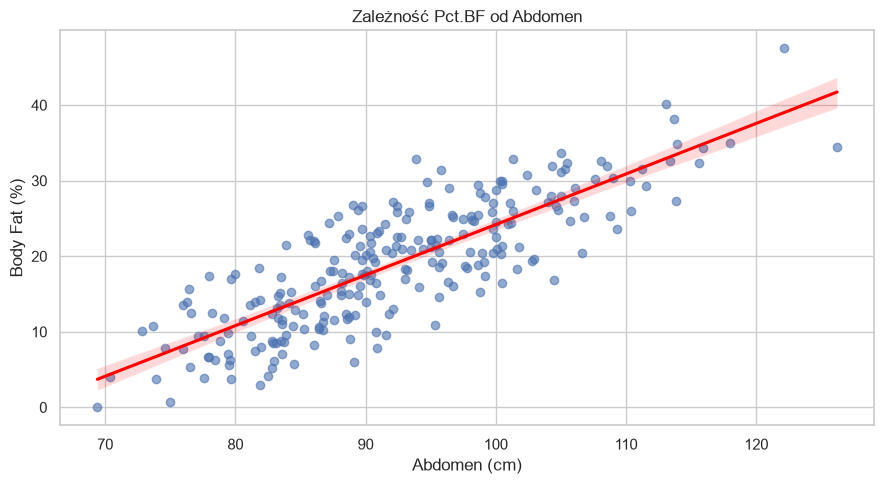

In [69]:
plt.figure(figsize=(9, 5))

sns.regplot(
    data=df,
    x="Abdomen",
    y="Pct.BF",
    scatter_kws={"alpha": 0.6},
    line_kws={"color": "red"}
)

plt.title("Zależność Pct.BF od Abdomen")
plt.xlabel("Abdomen (cm)")
plt.ylabel("Body Fat (%)")
plt.tight_layout()
plt.show()

## Diagnostyka modelu M5

W kolejnym etapie przeprowadzono diagnostykę modelu M5,
wykorzystującego zmienne `Weight` oraz `Abdomen`.

Analiza obejmuje porównanie wartości rzeczywistych
i przewidywanych, ocenę rozkładu reszt oraz sprawdzenie,
czy błędy modelu wykazują określone wzorce.

In [72]:
# Predykcje dla zbioru testowego
X_test_m5 = sm.add_constant(
    X_test[["Weight", "Abdomen"]]
)

Y_pred_m5 = model_m5.predict(X_test_m5)

# Reszty modelu
residuals = Y_test - Y_pred_m5

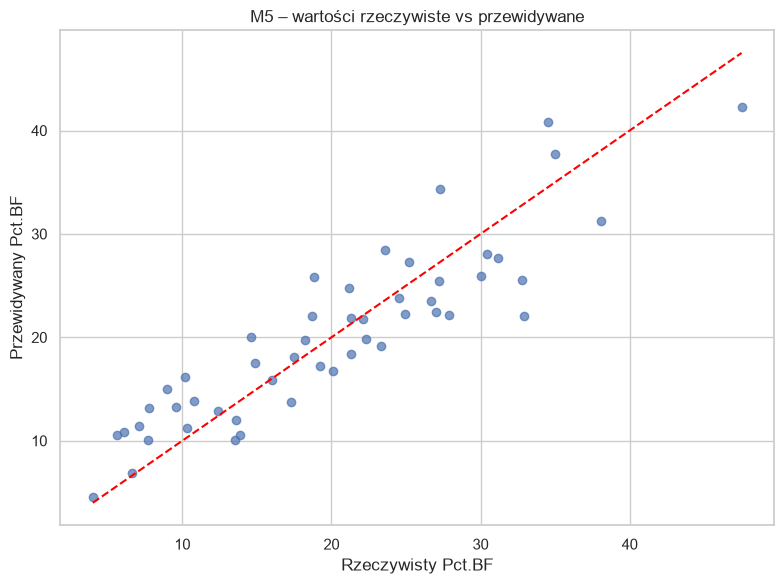

In [74]:
plt.figure(figsize=(8, 6))

plt.scatter(Y_test, Y_pred_m5, alpha=0.7)

min_val = min(Y_test.min(), Y_pred_m5.min())
max_val = max(Y_test.max(), Y_pred_m5.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--",
    color="red"
)

plt.xlabel("Rzeczywisty Pct.BF")
plt.ylabel("Przewidywany Pct.BF")
plt.title("M5 – wartości rzeczywiste vs przewidywane")

plt.tight_layout()
plt.show()

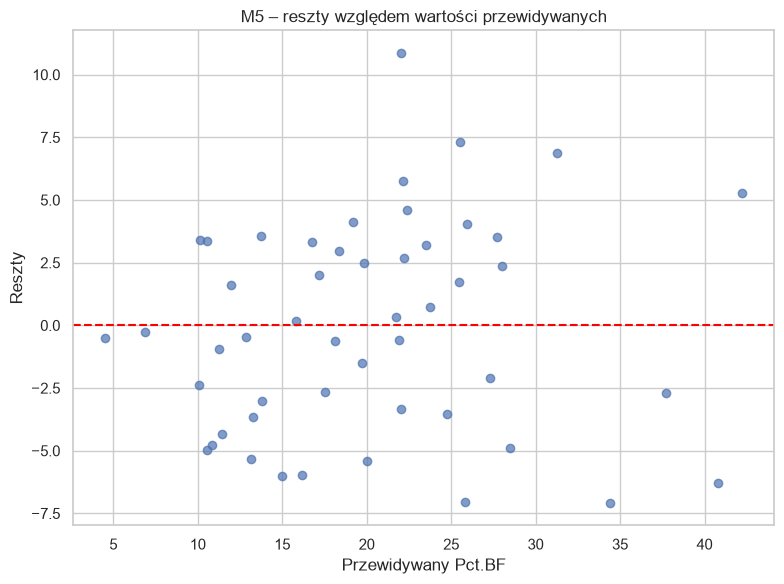

In [75]:
plt.figure(figsize=(8, 6))

plt.scatter(Y_pred_m5, residuals, alpha=0.7)

plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Przewidywany Pct.BF")
plt.ylabel("Reszty")
plt.title("M5 – reszty względem wartości przewidywanych")

plt.tight_layout()
plt.show()

### Analiza rozkładu reszt

W celu oceny rozkładu błędów predykcji przygotowano
histogram reszt modelu M5. Pozwala on sprawdzić,
czy reszty są skupione wokół zera i czy ich rozkład
jest zbliżony do rozkładu normalnego.

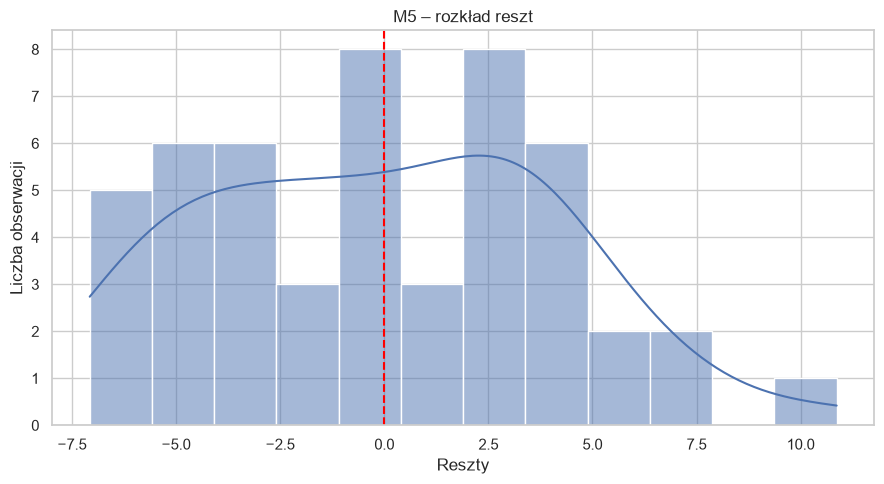

In [76]:
plt.figure(figsize=(9, 5))

sns.histplot(
    residuals,
    bins=12,
    kde=True
)

plt.axvline(0, color="red", linestyle="--")

plt.title("M5 – rozkład reszt")
plt.xlabel("Reszty")
plt.ylabel("Liczba obserwacji")

plt.tight_layout()
plt.show()

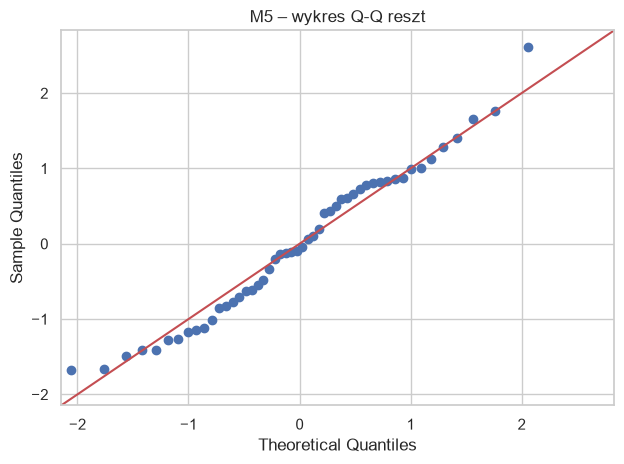

In [77]:
sm.qqplot(
    residuals,
    line="45",
    fit=True
)

plt.title("M5 – wykres Q-Q reszt")
plt.tight_layout()
plt.show()

In [78]:
from scipy.stats import jarque_bera

jb_stat, jb_pvalue = jarque_bera(residuals)

print("Jarque-Bera statistic:", jb_stat)
print("p-value:", jb_pvalue)

Jarque-Bera statistic: 1.1271332385434267
p-value: 0.5691754073884825


## Analiza współliniowości – VIF

W celu zbadania współliniowości pomiędzy zmiennymi
objaśniającymi obliczono współczynnik VIF
(Variance Inflation Factor).

Pozwala on określić, w jakim stopniu dany predyktor
jest wyjaśniany przez pozostałe zmienne objaśniające.
Wysokie wartości VIF mogą wskazywać na problemy
związane ze współliniowością i stabilnością
współczynników regresji.

In [79]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Macierz predyktorów z wyrazem wolnym
X_vif = sm.add_constant(X_train)

# Obliczenie VIF dla każdej zmiennej
vif_data = pd.DataFrame({
    "Variable": X_vif.columns,
    "VIF": [
        variance_inflation_factor(X_vif.values, i)
        for i in range(X_vif.shape[1])
    ]
})

# Pomijamy wyraz wolny
vif_data = vif_data[vif_data["Variable"] != "const"]

# Sortowanie malejąco
vif_data = vif_data.sort_values(
    by="VIF",
    ascending=False
)

display(vif_data.round(3))

,Variable,VIF
2,Weight,40.716
7,Hip,12.066
6,Abdomen,11.006
5,Chest,9.940
8,Thigh,7.871
9,Knee,5.069
4,Neck,3.630
3,Height,3.403
11,Bicep,3.105
13,Wrist,3.014


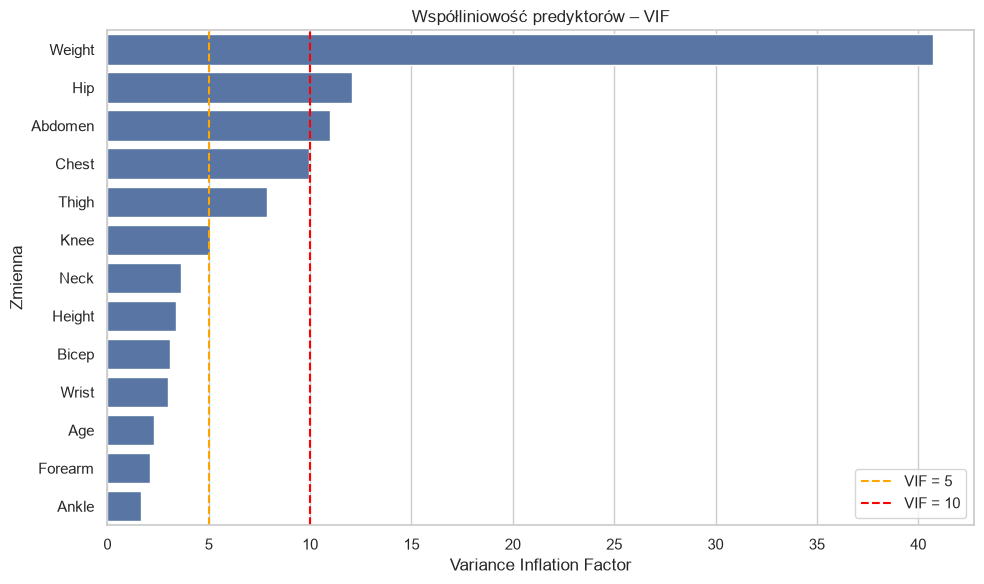

In [81]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=vif_data,
    x="VIF",
    y="Variable"
)

plt.axvline(
    x=5,
    color="orange",
    linestyle="--",
    label="VIF = 5"
)

plt.axvline(
    x=10,
    color="red",
    linestyle="--",
    label="VIF = 10"
)

plt.title("Współliniowość predyktorów – VIF")
plt.xlabel("Variance Inflation Factor")
plt.ylabel("Zmienna")

plt.legend()
plt.tight_layout()
plt.show()

### Analiza współliniowości predyktorów

W celu oceny współliniowości pomiędzy predyktorami modelu pełnego obliczono współczynniki VIF.

Najwyższą wartość uzyskano dla zmiennej `Weight` (VIF = 40,716). Wysokie wartości wystąpiły również dla `Hip` (12,066) oraz `Abdomen` (11,006). Podwyższoną współliniowość zaobserwowano także dla zmiennych `Chest`, `Thigh` oraz `Knee`.

Wyniki wskazują, że część zmiennych opisujących budowę ciała dostarcza podobnych informacji. Może to utrudniać precyzyjne oszacowanie indywidualnego wpływu poszczególnych predyktorów na zmienną objaśnianą.

W związku z tym dalsza selekcja zmiennych powinna uwzględniać nie tylko istotność statystyczną współczynników, ale również współliniowość pomiędzy predyktorami. Szczególnej uwagi wymagają zmienne `Weight`, `Hip` oraz `Abdomen`.

# Eliminacja wsteczna – Backward Elimination

W celu ograniczenia liczby predyktorów zastosowano
procedurę eliminacji wstecznej.

Procedura rozpoczyna się od modelu pełnego, zawierającego
wszystkie 13 predyktorów. W kolejnych iteracjach usuwana
jest zmienna o najwyższej wartości p-value, jeżeli
przekracza ona przyjęty poziom istotności α = 0.05.

Po każdym usunięciu model jest ponownie dopasowywany.
Proces kończy się, gdy wszystkie pozostawione predyktory
osiągną przyjęty poziom istotności statystycznej.

In [82]:
def backward_elimination(X, y, significance_level=0.05):

    selected_features = list(X.columns)
    history = []

    while True:

        X_model = sm.add_constant(X[selected_features])
        model = sm.OLS(y, X_model).fit()

        # P-value bez wyrazu wolnego
        p_values = model.pvalues.drop("const")

        # Znajdź zmienną z najwyższym p-value
        worst_feature = p_values.idxmax()
        worst_p_value = p_values.max()

        history.append({
            "Removed variable": worst_feature if worst_p_value > significance_level else "-",
            "p-value": worst_p_value,
            "Number of predictors": len(selected_features),
            "Adjusted R2": model.rsquared_adj,
            "AIC": model.aic
        })

        # Warunek zakończenia
        if worst_p_value <= significance_level:
            break

        # Usuń zmienną o najwyższym p-value
        selected_features.remove(worst_feature)

    return model, selected_features, pd.DataFrame(history)

In [84]:
model_backward, selected_features, elimination_history = (
    backward_elimination(X_train, Y_train)
)

display(elimination_history.round(4))

,Removed variable,p-value,Number of predictors,Adjusted R2,AIC
0,Knee,0.966,13,0.709,1160.988
1,Weight,0.677,12,0.711,1158.990
2,Hip,0.656,11,0.712,1157.176
3,Ankle,0.472,10,0.713,1155.388
4,Bicep,0.436,9,0.714,1153.936
5,Chest,0.387,8,0.715,1152.576
6,Thigh,0.199,7,0.715,1151.360
7,Forearm,0.150,6,0.714,1151.084
8,Age,0.081,5,0.712,1151.241
9,-,0.020,4,0.709,1152.381


In [85]:
print("Wybrane predyktory:", selected_features)

display(model_backward.summary())

Wybrane predyktory: ['Height', 'Neck', 'Abdomen', 'Wrist']


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 Pct.BF   R-squared:                       0.715
Model:                            OLS   Adj. R-squared:                  0.709
Method:                 Least Squares   F-statistic:                     122.4
Date:                Sun, 08 Nov 2026   Prob (F-statistic):           4.65e-52
Time:                        21:03:22   Log-Likelihood:                -571.19
No. Observations:                 200   AIC:                             1152.
Df Residuals:                     195   BIC:                             1169.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         11.2690      9.114      1.236      0.218      -6.705      29.243
Height        -0.3878      0.132     -2.943      0.004      -0.648      -0.128
Neck          -0.5275      0.225     -2.340      0.020      -0.972      -0.083
Abdomen        0.8374      0.045     18.785      0.000       0.749       0.925
Wrist         -1.2179      0.493     -2.470      0.014      -2.190      -0.245
==============================================================================
Omnibus:                        3.870   Durbin-Watson:                   2.010
Prob(Omnibus):                  0.144   Jarque-Bera (JB):                2.493
Skew:                           0.037   Prob(JB):                        0.288
Kurtosis:                       2.458   Cond. No.                     3.73e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 3.73e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [87]:
X_test_backward = sm.add_constant(
    X_test[selected_features],
    has_constant="add"
)

Y_pred_backward = model_backward.predict(X_test_backward)

backward_test_results = {
    "Model": "Backward Elimination",
    "R2 test": r2_score(Y_test, Y_pred_backward),
    "MAE": mean_absolute_error(Y_test, Y_pred_backward),
    "RMSE": np.sqrt(mean_squared_error(Y_test, Y_pred_backward))
}

display(pd.DataFrame([backward_test_results]).round(4))

,Model,R2 test,MAE,RMSE
0,Backward Elimination,0.783,3.804,4.485


In [88]:
final_comparison = pd.concat(
    [
        test_comparison,
        pd.DataFrame([backward_test_results])
    ],
    ignore_index=True
)

display(
    final_comparison
    .sort_values("R2 test", ascending=False)
    .round(4)
)

,Model,R2 test,MAE,RMSE
4,M5 - Weight + Abdomen,0.811,3.534,4.183
6,M7 - Weight + Height + Abdomen,0.811,3.572,4.184
7,M8 - Full model,0.797,3.724,4.333
5,M6 - Height + Abdomen,0.794,3.755,4.368
8,Backward Elimination,0.783,3.804,4.485
2,M3 - Abdomen,0.753,3.856,4.778
3,M4 - Weight + Height,0.654,4.691,5.664
1,M2 - Weight,0.435,5.462,7.232
0,M1 - Height,-0.023,7.924,9.733


In [89]:
X_backward_vif = sm.add_constant(
    X_train[selected_features]
)

vif_backward = pd.DataFrame({
    "Variable": X_backward_vif.columns,
    "VIF": [
        variance_inflation_factor(
            X_backward_vif.values, i
        )
        for i in range(X_backward_vif.shape[1])
    ]
})

vif_backward = vif_backward[
    vif_backward["Variable"] != "const"
].sort_values("VIF", ascending=False)

display(vif_backward.round(3))

,Variable,VIF
2,Neck,2.791
4,Wrist,2.161
3,Abdomen,2.011
1,Height,1.191


### Porównanie współliniowości przed i po eliminacji zmiennych

Po przeprowadzeniu eliminacji wstecznej ponownie obliczono współczynniki VIF dla pozostawionych predyktorów. Wszystkie uzyskane wartości były niższe od 3, co wskazuje na brak istotnego problemu współliniowości w uproszczonym modelu.

Największą poprawę zaobserwowano dla zmiennej `Abdomen`, której VIF zmniejszył się z 11,006 do 2,011. Oznacza to, że usunięcie części silnie powiązanych predyktorów pozwoliło uzyskać stabilniejszy zestaw zmiennych objaśniających.

## Walidacja krzyżowa modeli

W celu sprawdzenia stabilności jakości modeli zastosowano
5-krotną walidację krzyżową (5-fold cross-validation).

Walidację przeprowadzono na zbiorze treningowym. W każdej
iteracji model był trenowany na czterech częściach danych,
a oceniany na pozostałej części.

Porównano modele M5, M7, M8 oraz model uzyskany
w wyniku eliminacji wstecznej.

In [95]:
from sklearn.model_selection import KFold, cross_validate
from sklearn.linear_model import LinearRegression

# Definicje modeli i ich predyktorów
cv_models = {
    "M5 - Weight + Abdomen": ["Weight", "Abdomen"],
    "M7 - Weight + Height + Abdomen": [
        "Weight", "Height", "Abdomen"
    ],
    "M8 - Full model": X_train.columns.tolist(),
    "Backward - 4 predictors": selected_features
}

# Pięć podziałów z losowym przemieszaniem obserwacji
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=4
)

cv_results = []

for name, features in cv_models.items():

    model = LinearRegression()

    scores = cross_validate(
        model,
        X_train[features],
        Y_train,
        cv=cv,
        scoring={
            "R2": "r2",
            "MAE": "neg_mean_absolute_error",
            "RMSE": "neg_root_mean_squared_error"
        }
    )

    cv_results.append({
        "Model": name,
        "R2 mean": scores["test_R2"].mean(),
        "R2 std": scores["test_R2"].std(),
        "MAE mean": -scores["test_MAE"].mean(),
        "MAE std": scores["test_MAE"].std(),
        "RMSE mean": -scores["test_RMSE"].mean(),
        "RMSE std": scores["test_RMSE"].std()
    })

cv_comparison = pd.DataFrame(cv_results)

display(cv_comparison.round(4))

,Model,R2 mean,R2 std,MAE mean,MAE std,RMSE mean,RMSE std
0,M5 - Weight + Abdomen,0.658,0.098,3.636,0.399,4.486,0.364
1,M7 - Weight + Height + Abdomen,0.660,0.097,3.628,0.375,4.475,0.387
2,M8 - Full model,0.663,0.109,3.671,0.460,4.444,0.396
3,Backward - 4 predictors,0.681,0.108,3.547,0.471,4.322,0.426


## Wielokrotna walidacja krzyżowa – Repeated K-Fold

W celu dokładniejszej oceny stabilności modeli zastosowano
powtórzoną 5-krotną walidację krzyżową.

Procedurę powtórzono pięciokrotnie, uzyskując łącznie
25 ocen każdego modelu.

Dzięki wielokrotnemu losowaniu podziałów ograniczono
zależność wyników od pojedynczego podziału danych.

In [98]:
from sklearn.model_selection import RepeatedKFold
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error
from sklearn.linear_model import LinearRegression

repeated_cv = RepeatedKFold(
    n_splits=5,
    n_repeats=5,
    random_state=4
)

fold_results = []

for name, features in cv_models.items():

    for fold, (train_idx, val_idx) in enumerate(
        repeated_cv.split(X_train),
        start=1
    ):

        X_fold_train = X_train.iloc[train_idx][features]
        X_fold_val = X_train.iloc[val_idx][features]

        Y_fold_train = Y_train.iloc[train_idx]
        Y_fold_val = Y_train.iloc[val_idx]

        model = LinearRegression()
        model.fit(X_fold_train, Y_fold_train)

        Y_fold_pred = model.predict(X_fold_val)

        fold_results.append({
            "Model": name,
            "Fold": fold,
            "R2": r2_score(Y_fold_val, Y_fold_pred),
            "MAE": mean_absolute_error(Y_fold_val, Y_fold_pred),
            "RMSE": root_mean_squared_error(
                Y_fold_val, Y_fold_pred
            )
        })

fold_results = pd.DataFrame(fold_results)

display(fold_results.head(10))

,Model,Fold,R2,MAE,RMSE
0,M5 - Weight + Abdomen,1,0.473,4.313,5.025
1,M5 - Weight + Abdomen,2,0.666,3.486,4.551
2,M5 - Weight + Abdomen,3,0.740,3.732,4.589
3,M5 - Weight + Abdomen,4,0.673,3.561,4.365
4,M5 - Weight + Abdomen,5,0.741,3.088,3.899
5,M5 - Weight + Abdomen,6,0.511,4.000,4.813
6,M5 - Weight + Abdomen,7,0.705,3.618,4.449
7,M5 - Weight + Abdomen,8,0.728,3.147,3.910
8,M5 - Weight + Abdomen,9,0.731,3.895,4.684
9,M5 - Weight + Abdomen,10,0.643,3.503,4.461


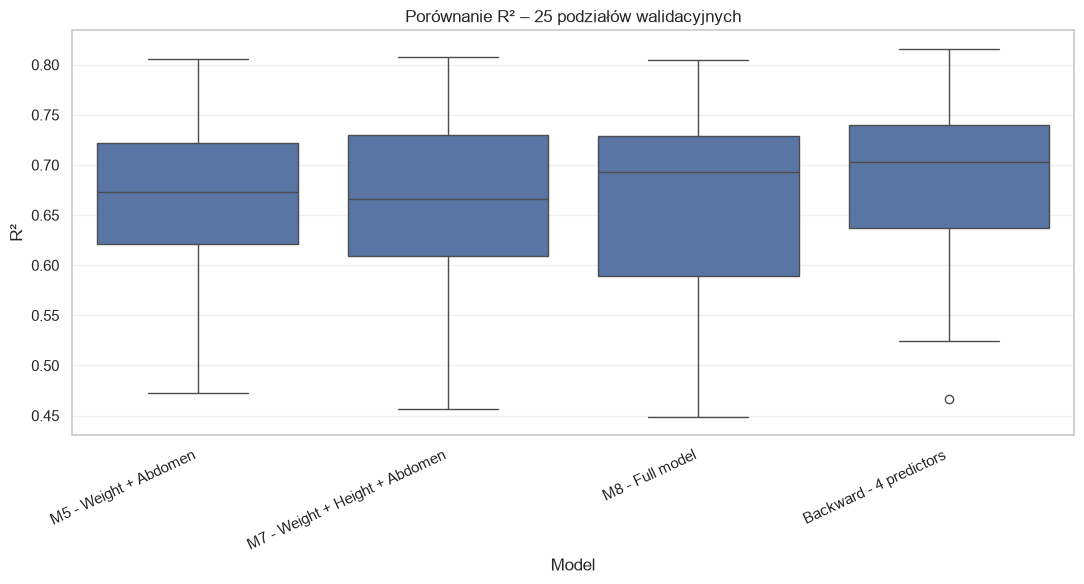

In [99]:
plt.figure(figsize=(11, 6))

sns.boxplot(
    data=fold_results,
    x="Model",
    y="R2"
)

plt.title("Porównanie R² – 25 podziałów walidacyjnych")
plt.xlabel("Model")
plt.ylabel("R²")
plt.xticks(rotation=25, ha="right")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

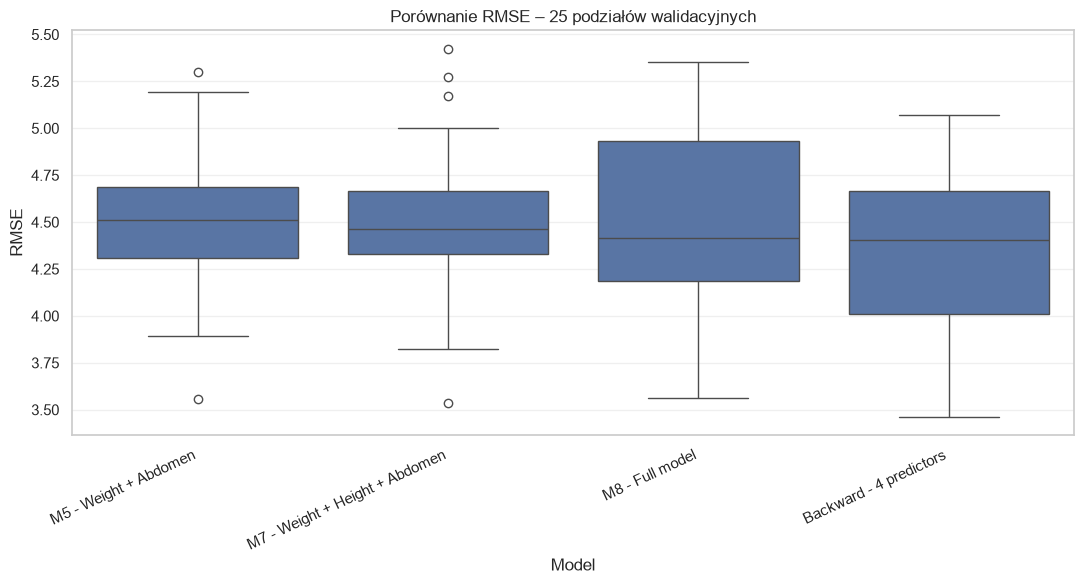

In [100]:
plt.figure(figsize=(11, 6))

sns.boxplot(
    data=fold_results,
    x="Model",
    y="RMSE"
)

plt.title("Porównanie RMSE – 25 podziałów walidacyjnych")
plt.xlabel("Model")
plt.ylabel("RMSE")
plt.xticks(rotation=25, ha="right")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## Wybór końcowego modelu przewidującego Pct.BF

Na podstawie przeprowadzonych analiz porównano modele wykorzystujące różną liczbę predyktorów. Uwzględniono dopasowanie do zbioru treningowego, jakość predykcji na zbiorze testowym, wyniki powtórzonej walidacji krzyżowej oraz złożoność modeli.

Najlepszy wynik na zbiorze testowym uzyskał model M5, wykorzystujący zmienne `Weight` oraz `Abdomen`. Na zbiorze treningowym osiągnął $R^2 = 0{,}688$ oraz skorygowany współczynnik determinacji $Adjusted\ R^2 = 0{,}685$. Na zbiorze testowym uzyskano $R^2 = 0{,}811$, MAE = 3,534 oraz RMSE = 4,183.

Model charakteryzuje się niewielką liczbą predyktorów i dobrą jakością predykcji na zbiorze testowym. Z tego względu został wybrany jako główny model do przewidywania procentowej zawartości tkanki tłuszczowej.

Warto jednak zauważyć, że w powtórzonej walidacji krzyżowej najlepsze średnie wyniki uzyskał model otrzymany metodą eliminacji wstecznej. Oznacza to, że wybór modelu zależy częściowo od zastosowanej metody oceny. M5 uznano za preferowany ze względu na wyniki na wydzielonym zbiorze testowym oraz prostszą strukturę.

In [117]:
display(model_m5.summary())

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 Pct.BF   R-squared:                       0.688
Model:                            OLS   Adj. R-squared:                  0.685
Method:                 Least Squares   F-statistic:                     217.2
Date:                Sun, 08 Nov 2026   Prob (F-statistic):           1.52e-50
Time:                        21:24:14   Log-Likelihood:                -580.33
No. Observations:                 200   AIC:                             1167.
Df Residuals:                     197   BIC:                             1177.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        -46.4716      3.150    -14.751      0.000     -52.684     -40.259
Weight        -0.1212      0.024     -4.979      0.000      -0.169      -0.073
Abdomen        0.9438      0.065     14.452      0.000       0.815       1.073
==============================================================================
Omnibus:                        4.800   Durbin-Watson:                   1.962
Prob(Omnibus):                  0.091   Jarque-Bera (JB):                2.836
Skew:                          -0.002   Prob(JB):                        0.242
Kurtosis:                       2.417   Cond. No.                     2.01e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 2.01e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

## Dodatkowy model – przewidywanie masy ciała (Weight)

W dodatkowej analizie podjęto próbę przewidywania masy
ciała (`Weight`) na podstawie pozostałych pomiarów
antropometrycznych.

W pierwszej kolejności zbadano zależność pomiędzy masą
ciała a obwodem brzucha (`Abdomen`).

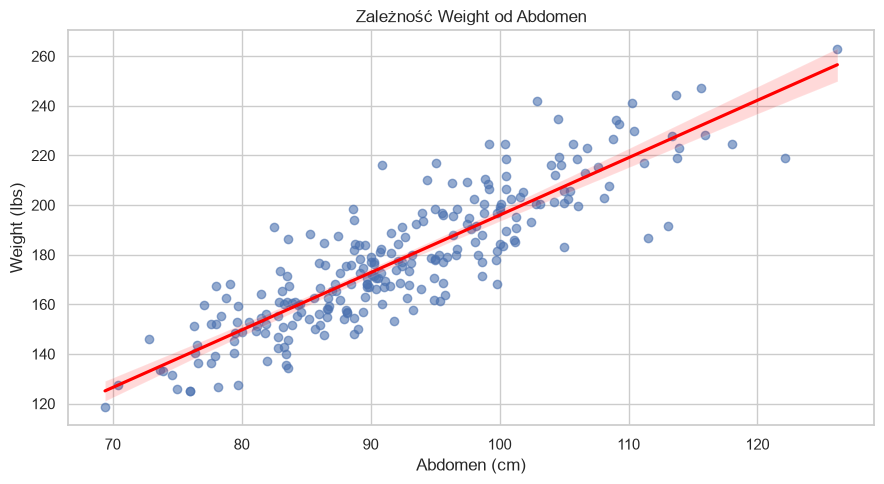

In [101]:
plt.figure(figsize=(9, 5))

sns.regplot(
    data=df,
    x="Abdomen",
    y="Weight",
    scatter_kws={"alpha": 0.6},
    line_kws={"color": "red"}
)

plt.title("Zależność Weight od Abdomen")
plt.xlabel("Abdomen (cm)")
plt.ylabel("Weight (lbs)")

plt.tight_layout()
plt.show()

In [105]:
y_weight_train = df.loc[X_train.index, "Weight"]
y_weight_test = df.loc[X_test.index, "Weight"]

model_w1 = sm.OLS(
    y_weight_train,
    sm.add_constant(X_train[["Abdomen"]])
).fit()

display(model_w1.summary())

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 Weight   R-squared:                       0.749
Model:                            OLS   Adj. R-squared:                  0.747
Method:                 Least Squares   F-statistic:                     590.0
Date:                Sun, 08 Nov 2026   Prob (F-statistic):           2.68e-61
Time:                        21:15:12   Log-Likelihood:                -795.14
No. Observations:                 200   AIC:                             1594.
Df Residuals:                     198   BIC:                             1601.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        -36.6842      8.821     -4.159      0.000     -54.080     -19.289
Abdomen        2.3217      0.096     24.290      0.000       2.133       2.510
==============================================================================
Omnibus:                        4.813   Durbin-Watson:                   2.010
Prob(Omnibus):                  0.090   Jarque-Bera (JB):                4.487
Skew:                           0.298   Prob(JB):                        0.106
Kurtosis:                       3.428   Cond. No.                         889.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [112]:
# Model W2 – Abdomen + Height
model_w2 = sm.OLS(
    y_weight_train,
    sm.add_constant(X_train[["Abdomen", "Height"]])
).fit()

# Model W3 – wszystkie dostępne pomiary antropometryczne
weight_features = [
    col for col in X_train.columns
    if col not in ["Weight", "Pct.BF", "Density"]
]

model_w3 = sm.OLS(
    y_weight_train,
    sm.add_constant(X_train[weight_features])
).fit()

display(model_w3.summary())

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 Weight   R-squared:                       0.975
Model:                            OLS   Adj. R-squared:                  0.974
Method:                 Least Squares   F-statistic:                     618.9
Date:                Sun, 08 Nov 2026   Prob (F-statistic):          1.89e-143
Time:                        21:16:52   Log-Likelihood:                -562.60
No. Observations:                 200   AIC:                             1151.
Df Residuals:                     187   BIC:                             1194.
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       -331.4609      9.994    -33.167      0.000    -351.175    -311.746
Age           -0.0742      0.034     -2.151      0.033      -0.142      -0.006
Height         2.0684      0.157     13.189      0.000       1.759       2.378
Neck           0.9015      0.243      3.714      0.000       0.423       1.380
Chest          0.9260      0.101      9.126      0.000       0.726       1.126
Abdomen        0.4300      0.097      4.431      0.000       0.239       0.621
Hip            0.8081      0.159      5.080      0.000       0.494       1.122
Thigh          0.5700      0.168      3.400      0.001       0.239       0.901
Knee           0.4960      0.286      1.734      0.084      -0.068       1.060
Ankle          0.4685      0.222      2.107      0.036       0.030       0.907
Bicep          0.5308      0.179      2.966      0.003       0.178       0.884
Forearm        0.4690      0.208      2.254      0.025       0.059       0.879
Wrist          1.4043      0.560      2.506      0.013       0.299       2.510
==============================================================================
Omnibus:                       40.699   Durbin-Watson:                   2.372
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              116.518
Skew:                          -0.831   Prob(JB):                     4.99e-26
Kurtosis:                       6.349   Cond. No.                     7.15e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 7.15e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [110]:
weight_models = {
    "W1 - Abdomen": model_w1,
    "W2 - Abdomen + Height": model_w2,
    "W3 - Full model": model_w3
}

weight_comparison = pd.DataFrame([
    {
        "Model": name,
        "R2": model.rsquared,
        "Adjusted R2": model.rsquared_adj,
        "AIC": model.aic
    }
    for name, model in weight_models.items()
])

display(weight_comparison.round(4))

,Model,R2,Adjusted R2,AIC
0,W1 - Abdomen,0.749,0.748,1594.275
1,W2 - Abdomen + Height,0.877,0.875,1453.908
2,W3 - Full model,0.975,0.974,1151.200


In [111]:
weight_test_results = []

weight_feature_sets = {
    "W1 - Abdomen": ["Abdomen"],
    "W2 - Abdomen + Height": ["Abdomen", "Height"],
    "W3 - Full model": weight_features
}

for name, features in weight_feature_sets.items():

    X_test_model = sm.add_constant(
        X_test[features],
        has_constant="add"
    )

    prediction = weight_models[name].predict(X_test_model)

    weight_test_results.append({
        "Model": name,
        "R2 test": r2_score(y_weight_test, prediction),
        "MAE": mean_absolute_error(y_weight_test, prediction),
        "RMSE": np.sqrt(mean_squared_error(y_weight_test, prediction))
    })

display(pd.DataFrame(weight_test_results).round(4))

,Model,R2 test,MAE,RMSE
0,W1 - Abdomen,0.789,11.099,14.053
1,W2 - Abdomen + Height,0.920,6.243,8.683
2,W3 - Full model,0.982,3.357,4.112


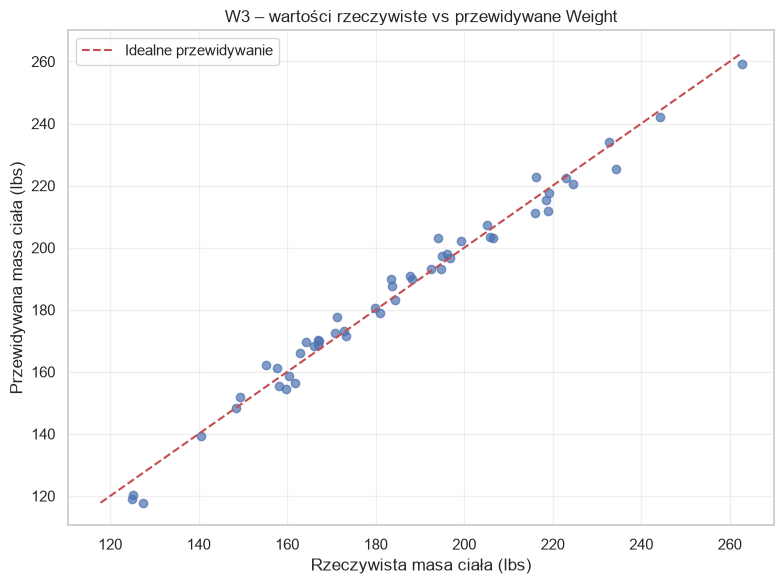

In [113]:
# Predykcja modelu W3 na zbiorze testowym
y_pred_w3 = model_w3.predict(
    sm.add_constant(X_test[weight_features], has_constant="add")
)

plt.figure(figsize=(8, 6))

plt.scatter(
    y_weight_test,
    y_pred_w3,
    alpha=0.7
)

# Linia idealnych predykcji
min_val = min(y_weight_test.min(), y_pred_w3.min())
max_val = max(y_weight_test.max(), y_pred_w3.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    "r--",
    label="Idealne przewidywanie"
)

plt.title("W3 – wartości rzeczywiste vs przewidywane Weight")
plt.xlabel("Rzeczywista masa ciała (lbs)")
plt.ylabel("Przewidywana masa ciała (lbs)")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

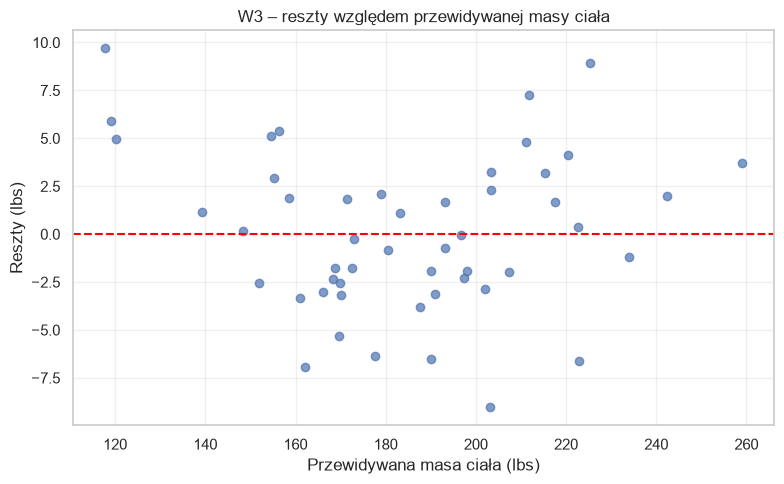

In [114]:
residuals_weight = y_weight_test - y_pred_w3

plt.figure(figsize=(8, 5))

plt.scatter(
    y_pred_w3,
    residuals_weight,
    alpha=0.7
)

plt.axhline(0, color="red", linestyle="--")

plt.title("W3 – reszty względem przewidywanej masy ciała")
plt.xlabel("Przewidywana masa ciała (lbs)")
plt.ylabel("Reszty (lbs)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

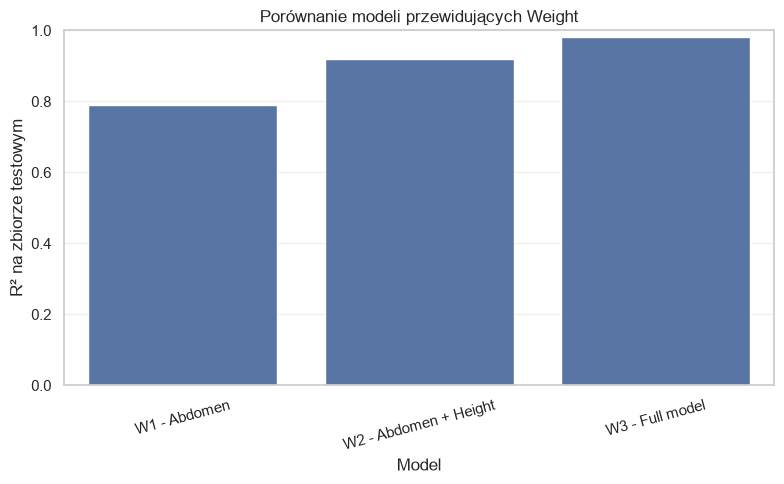

In [115]:
weight_test_df = pd.DataFrame(weight_test_results)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=weight_test_df,
    x="Model",
    y="R2 test"
)

plt.title("Porównanie modeli przewidujących Weight")
plt.xlabel("Model")
plt.ylabel("R² na zbiorze testowym")
plt.ylim(0, 1)
plt.xticks(rotation=15)

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Wizualna ocena modelu przewidującego masę ciała

Wykres wartości rzeczywistych i przewidywanych dla modelu W3 wskazuje na bardzo dobre dopasowanie predykcji do rzeczywistych wartości masy ciała. Większość obserwacji znajduje się blisko linii idealnego przewidywania.

Analiza wykresu reszt nie wskazuje na wyraźny systematyczny wzorzec błędów. Reszty są rozmieszczone po obu stronach poziomu zerowego, chociaż występują pojedyncze większe odchylenia.

Porównanie modeli wykazało, że zwiększenie liczby predyktorów poprawia jakość przewidywania masy ciała. Najlepszy wynik uzyskał model pełny W3, osiągając \(R^2 = 0{,}982\) na zbiorze testowym.

Wyniki wskazują, że pomiary antropometryczne dostarczają dużej ilości informacji przydatnych do przewidywania masy ciała.